# DSA211: Diagnosing and Remedying Nonlinearity in Bike-Sharing Demand Models
## Notebook 01: Exploratory Data Analysis (EDA)
**Group 2**: Kok Wai Ying, Lee Sin Yang, Lim Wei Lun Marcus, Samuel Teo Yuzhen, Tee Jing Yuan

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All code blocks below are labeled as AI-assisted. All modeling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below.


## 1. Environment Setup and Data Ingestion
*Code: Generated by AI Assistant*


In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Styling and visualization configurations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

figures_dir = os.path.join('..', 'figures')
os.makedirs(figures_dir, exist_ok=True)

# Load hourly bike-sharing dataset
data_path = os.path.join('..', 'data', 'hour.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'hour.csv')

df = pd.read_csv(data_path)
df['dteday'] = pd.to_datetime(df['dteday'])

print(f"Dataset successfully loaded. Total rows: {len(df):,}, Columns: {df.shape[1]}")
df.head()


Dataset successfully loaded. Total rows: 17,379, Columns: 17


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [24]:
# Inspect data schema and check for missing values
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

### Data Inspection Notes
**Author**: [Insert Name]  
<!-- Add your observations on data structure, row counts, missingness, and variable types here -->


## 2. Chronological Train / Test Split
*Code: Generated by AI Assistant*


In [25]:
# Chronological split: hold out final quarter of 2012 (Oct 1, 2012 to Dec 31, 2012)
split_date = pd.to_datetime('2012-10-01')

train_mask = df['dteday'] < split_date
test_mask = df['dteday'] >= split_date

train_df = df[train_mask].copy()
test_df = df[test_mask].copy()

# Add un-normalized variables for intuitive interpretation
train_df['temp_c'] = train_df['temp'] * 41.0
train_df['atemp_c'] = train_df['atemp'] * 50.0
train_df['hum_pct'] = train_df['hum'] * 100.0
train_df['windspeed_kmh'] = train_df['windspeed'] * 67.0

df['temp_c'] = df['temp'] * 41.0
df['atemp_c'] = df['atemp'] * 50.0
df['hum_pct'] = df['hum'] * 100.0
df['windspeed_kmh'] = df['windspeed'] * 67.0

print(f"Total observations: {len(df):,}")
print(f"Train set (Jan 2011 - Sep 2012): {len(train_df):,} ({len(train_df)/len(df)*100:.1f}%)")
print(f"Test set (Oct 2012 - Dec 2012) : {len(test_df):,} ({len(test_df)/len(df)*100:.1f}%)")


Total observations: 17,379
Train set (Jan 2011 - Sep 2012): 15,211 (87.5%)
Test set (Oct 2012 - Dec 2012) : 2,168 (12.5%)


### Split Justification & Decisions
**Author**: [Insert Name]  
<!-- Add your reasoning for using a chronological holdout over random splitting and how it addresses temporal autocorrelation here -->


---
## 3. Question 1: What is the Overall Trend of Bike Rental Usage?
*Code: Generated by AI Assistant*


In [26]:
# Daily aggregate trend across the full 2-year timeline
daily_trend = df.groupby('dteday').agg({
    'cnt': 'sum',
    'casual': 'sum',
    'registered': 'sum',
    'temp_c': 'mean'
}).reset_index()

daily_trend['cnt_7d_mavg'] = daily_trend['cnt'].rolling(window=7, center=True).mean()
daily_trend['cnt_30d_mavg'] = daily_trend['cnt'].rolling(window=30, center=True).mean()

# Year-over-year growth summary
tot_2011 = df[df['yr'] == 0]['cnt'].sum()
tot_2012 = df[df['yr'] == 1]['cnt'].sum()
mean_hr_2011 = df[df['yr'] == 0]['cnt'].mean()
mean_hr_2012 = df[df['yr'] == 1]['cnt'].mean()
growth_rate = ((tot_2012 - tot_2011) / tot_2011) * 100

print(f"2011 Total Rentals: {tot_2011:,} (Mean: {mean_hr_2011:.1f} rentals/hour)")
print(f"2012 Total Rentals: {tot_2012:,} (Mean: {mean_hr_2012:.1f} rentals/hour)")
print(f"Year-over-Year Growth Rate: {growth_rate:.2f}%")


2011 Total Rentals: 1,243,103 (Mean: 143.8 rentals/hour)
2012 Total Rentals: 2,049,576 (Mean: 234.7 rentals/hour)
Year-over-Year Growth Rate: 64.88%


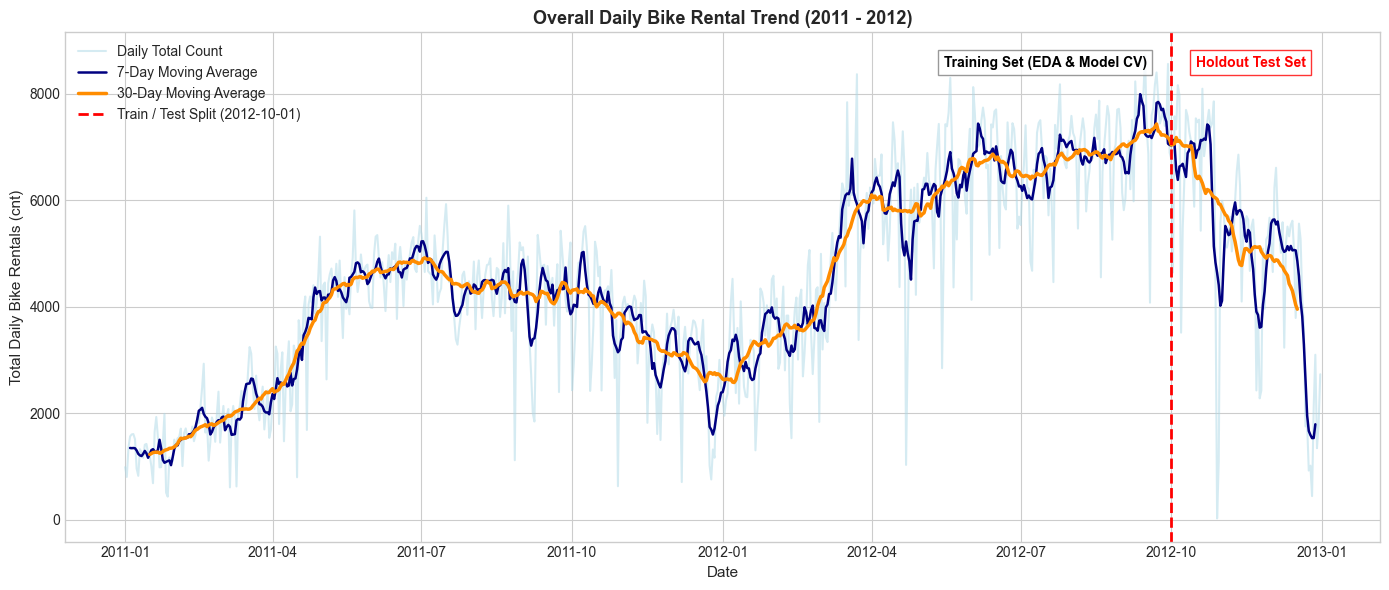

In [27]:
# Plot daily rental timeline with train/test boundary
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily_trend['dteday'], daily_trend['cnt'], color='lightblue', alpha=0.5, label='Daily Total Count')
ax.plot(daily_trend['dteday'], daily_trend['cnt_7d_mavg'], color='navy', linewidth=1.8, label='7-Day Moving Average')
ax.plot(daily_trend['dteday'], daily_trend['cnt_30d_mavg'], color='darkorange', linewidth=2.5, label='30-Day Moving Average')

ax.axvline(split_date, color='red', linestyle='--', linewidth=2, label='Train / Test Split (2012-10-01)')
ax.text(split_date - pd.Timedelta(days=15), 8500, 'Training Set (EDA & Model CV)', 
        color='black', ha='right', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))
ax.text(split_date + pd.Timedelta(days=15), 8500, 'Holdout Test Set', 
        color='red', ha='left', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, edgecolor='red'))

ax.set_title('Overall Daily Bike Rental Trend (2011 - 2012)', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Total Daily Bike Rentals (cnt)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


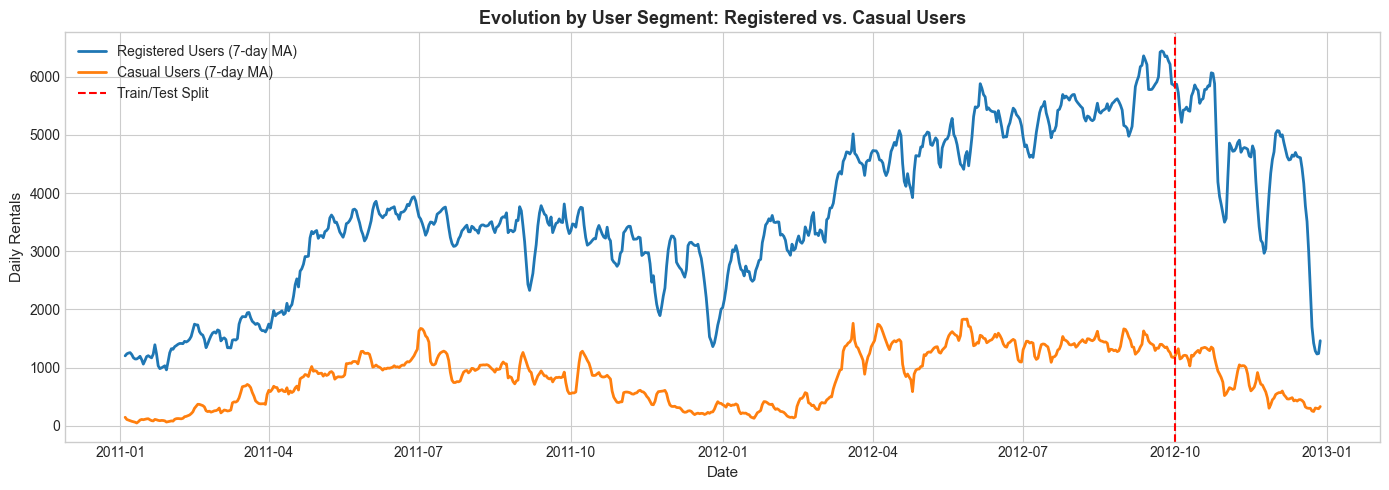

In [28]:
# Plot registered vs casual user evolution
daily_trend['cas_7d'] = daily_trend['casual'].rolling(7, center=True).mean()
daily_trend['reg_7d'] = daily_trend['registered'].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_trend['dteday'], daily_trend['reg_7d'], color='#1f77b4', linewidth=2, label='Registered Users (7-day MA)')
ax.plot(daily_trend['dteday'], daily_trend['cas_7d'], color='#ff7f0e', linewidth=2, label='Casual Users (7-day MA)')
ax.axvline(split_date, color='red', linestyle='--', label='Train/Test Split')

ax.set_title('Evolution by User Segment: Registered vs. Casual Users', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Daily Rentals')
ax.legend()
plt.tight_layout()
plt.show()


### Interpretation: Overall Trend
**Author**: [Insert Name]  
<!-- Add your written interpretation of long-term trend, growth, seasonality, and user differences here -->


---
## 4. Question 2: What is the Overall Distribution of Bike Rentals? Does it Follow Any Statistical Distribution?
*Code: Generated by AI Assistant*


In [29]:
# Target distribution descriptive statistics on training data
cnt_train = train_df['cnt'].values
mean_cnt = np.mean(cnt_train)
var_cnt = np.var(cnt_train, ddof=1)
std_cnt = np.std(cnt_train, ddof=1)
median_cnt = np.median(cnt_train)
skew_cnt = stats.skew(cnt_train)
kurt_cnt = stats.kurtosis(cnt_train)
dispersion_index = var_cnt / mean_cnt

print(f"--- Training Target (cnt) Descriptive Statistics (N = {len(cnt_train):,}) ---")
print(f"Mean                  : {mean_cnt:.2f}")
print(f"Median                : {median_cnt:.2f}")
print(f"Variance              : {var_cnt:.2f}")
print(f"Standard Deviation    : {std_cnt:.2f}")
print(f"Skewness              : {skew_cnt:.3f}")
print(f"Kurtosis              : {kurt_cnt:.3f}")
print(f"Dispersion Index (Var/Mean): {dispersion_index:.2f}")


--- Training Target (cnt) Descriptive Statistics (N = 15,211) ---
Mean                  : 185.23
Median                : 138.00
Variance              : 31654.89
Standard Deviation    : 177.92
Skewness              : 1.298
Kurtosis              : 1.512
Dispersion Index (Var/Mean): 170.90


In [30]:
# Parametric distribution fitting via Maximum Likelihood Estimation (MLE)
# 1. Normal
norm_stat, norm_p = stats.kstest(cnt_train, 'norm', args=(mean_cnt, std_cnt))
ll_norm = np.sum(stats.norm.logpdf(cnt_train, mean_cnt, std_cnt))

# 2. Gamma
shape_gam, loc_gam, scale_gam = stats.gamma.fit(cnt_train, floc=0)
gam_stat, gam_p = stats.kstest(cnt_train, 'gamma', args=(shape_gam, loc_gam, scale_gam))
ll_gam = np.sum(stats.gamma.logpdf(cnt_train, shape_gam, loc_gam, scale_gam))

# 3. Log-Normal
shape_ln, loc_ln, scale_ln = stats.lognorm.fit(cnt_train, floc=0)
ln_stat, ln_p = stats.kstest(cnt_train, 'lognorm', args=(shape_ln, loc_ln, scale_ln))
ll_ln = np.sum(stats.lognorm.logpdf(cnt_train, shape_ln, loc_ln, scale_ln))

# 4. Exponential
loc_exp, scale_exp = stats.expon.fit(cnt_train, floc=0)
exp_stat, exp_p = stats.kstest(cnt_train, 'expon', args=(loc_exp, scale_exp))
ll_exp = np.sum(stats.expon.logpdf(cnt_train, loc_exp, scale_exp))

# Goodness-of-fit comparison table
fit_comparison = pd.DataFrame({
    'Distribution': ['Gamma', 'Exponential', 'Log-Normal', 'Normal (Gaussian)'],
    'Parameters': [
        f"alpha={shape_gam:.3f}, scale={scale_gam:.1f}",
        f"scale={scale_exp:.1f}",
        f"sigma={shape_ln:.3f}, scale={scale_ln:.1f}",
        f"mu={mean_cnt:.1f}, sigma={std_cnt:.1f}"
    ],
    'Log-Likelihood': [ll_gam, ll_exp, ll_ln, ll_norm],
    'AIC': [2*2 - 2*ll_gam, 2*1 - 2*ll_exp, 2*2 - 2*ll_ln, 2*2 - 2*ll_norm],
    'KS-Statistic': [gam_stat, exp_stat, ln_stat, norm_stat],
    'KS p-value': [gam_p, exp_p, ln_p, norm_p]
}).sort_values('AIC')

fit_comparison


,Distribution,Parameters,Log-Likelihood,AIC,KS-Statistic,KS p-value
0,Gamma,"alpha=0.833, scale=222.4",-94458.083461,188920.166922,0.051085,6.124002e-35
1,Exponential,scale=185.2,-94636.340110,189274.680220,0.072124,2.973707e-69
2,Log-Normal,"sigma=1.487, scale=91.2",-96261.986172,192527.972343,0.116446,3.747680e-180
3,Normal (Gaussian),"mu=185.2, sigma=177.9",-100396.093645,200796.187290,0.150230,3.668605e-300


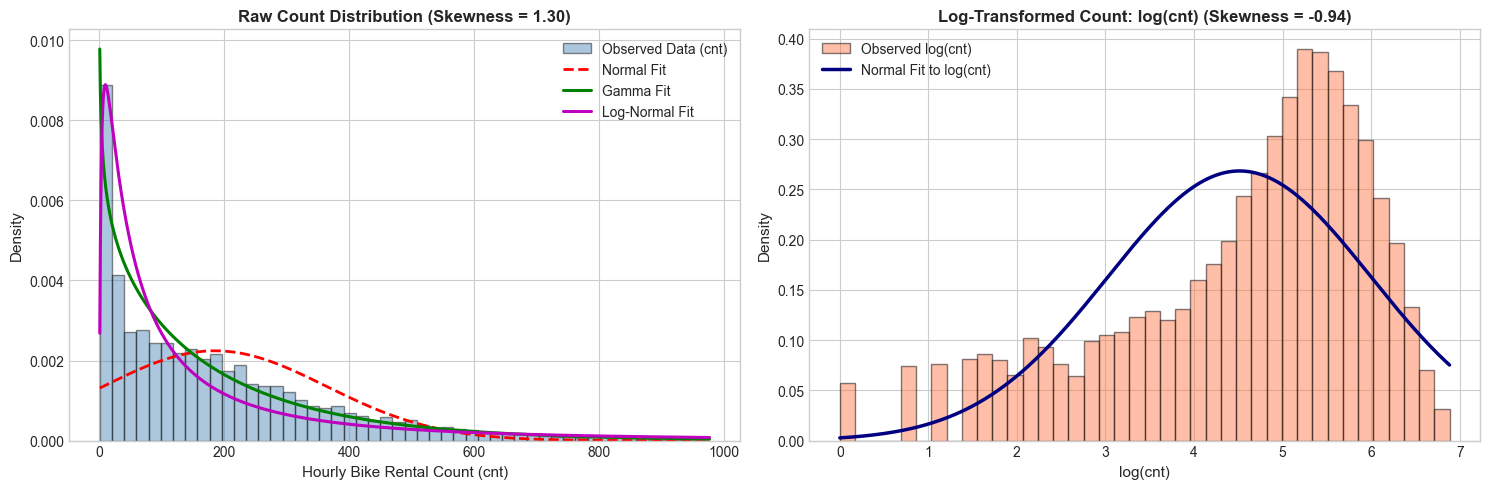

In [31]:
# Plot empirical density vs fitted curves and log-transformed count
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x_grid = np.linspace(1, cnt_train.max(), 1000)

# Raw count density
axes[0].hist(cnt_train, bins=50, density=True, alpha=0.45, color='steelblue', edgecolor='black', label='Observed Data (cnt)')
axes[0].plot(x_grid, stats.norm.pdf(x_grid, mean_cnt, std_cnt), 'r--', linewidth=2, label='Normal Fit')
axes[0].plot(x_grid, stats.gamma.pdf(x_grid, shape_gam, loc_gam, scale_gam), 'g-', linewidth=2.2, label='Gamma Fit')
axes[0].plot(x_grid, stats.lognorm.pdf(x_grid, shape_ln, loc_ln, scale_ln), 'm-', linewidth=2.2, label='Log-Normal Fit')
axes[0].set_title(f'Raw Count Distribution (Skewness = {skew_cnt:.2f})', fontweight='bold')
axes[0].set_xlabel('Hourly Bike Rental Count (cnt)')
axes[0].set_ylabel('Density')
axes[0].legend()

# Log-transformed count density
log_cnt = np.log(cnt_train)
log_mean, log_std = np.mean(log_cnt), np.std(log_cnt, ddof=1)
log_skew, log_kurt = stats.skew(log_cnt), stats.kurtosis(log_cnt)

axes[1].hist(log_cnt, bins=40, density=True, alpha=0.5, color='coral', edgecolor='black', label='Observed log(cnt)')
x_log_grid = np.linspace(log_cnt.min(), log_cnt.max(), 500)
axes[1].plot(x_log_grid, stats.norm.pdf(x_log_grid, log_mean, log_std), 'navy', linewidth=2.5, 
             label=f'Normal Fit to log(cnt)')
axes[1].set_title(f'Log-Transformed Count: log(cnt) (Skewness = {log_skew:.2f})', fontweight='bold')
axes[1].set_xlabel('log(cnt)')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()


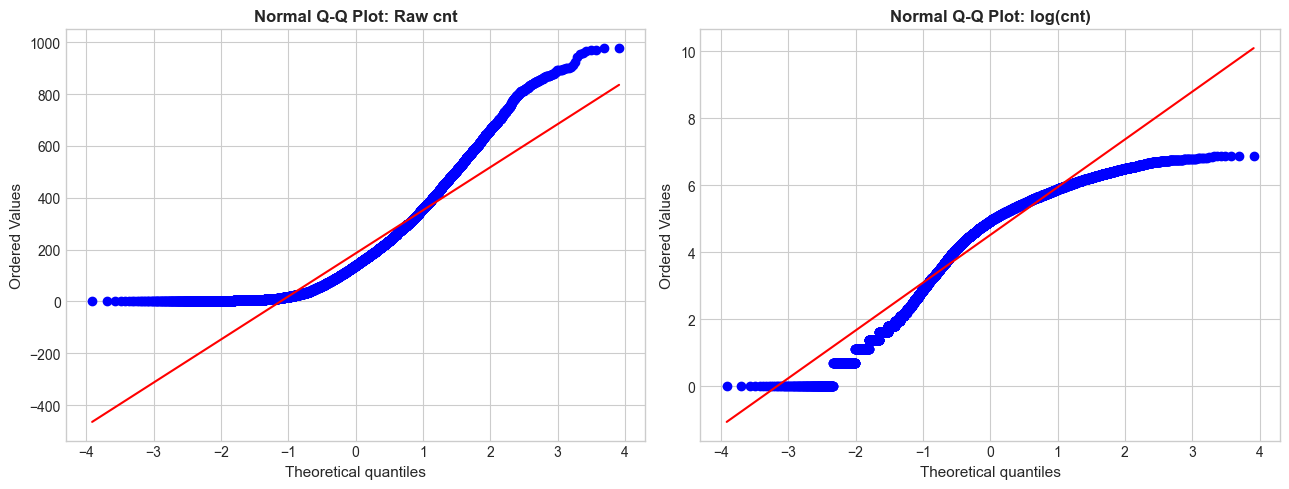

In [32]:
# Normal Q-Q Plots: raw count vs log(cnt)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stats.probplot(cnt_train, dist="norm", plot=axes[0])
axes[0].set_title('Normal Q-Q Plot: Raw cnt', fontweight='bold')

stats.probplot(log_cnt, dist="norm", plot=axes[1])
axes[1].set_title('Normal Q-Q Plot: log(cnt)', fontweight='bold')
plt.tight_layout()
plt.show()


### Interpretation & Modeling Decisions: Target Distribution
**Author**: [Insert Name]  
<!-- Add your written evaluation of overdispersion, parametric distribution fit, log transformation, and back-transformation decisions here -->


---
## 5. Question 3: How Do Different Time Aspects Affect Bike Rental?
*Code: Generated by AI Assistant*


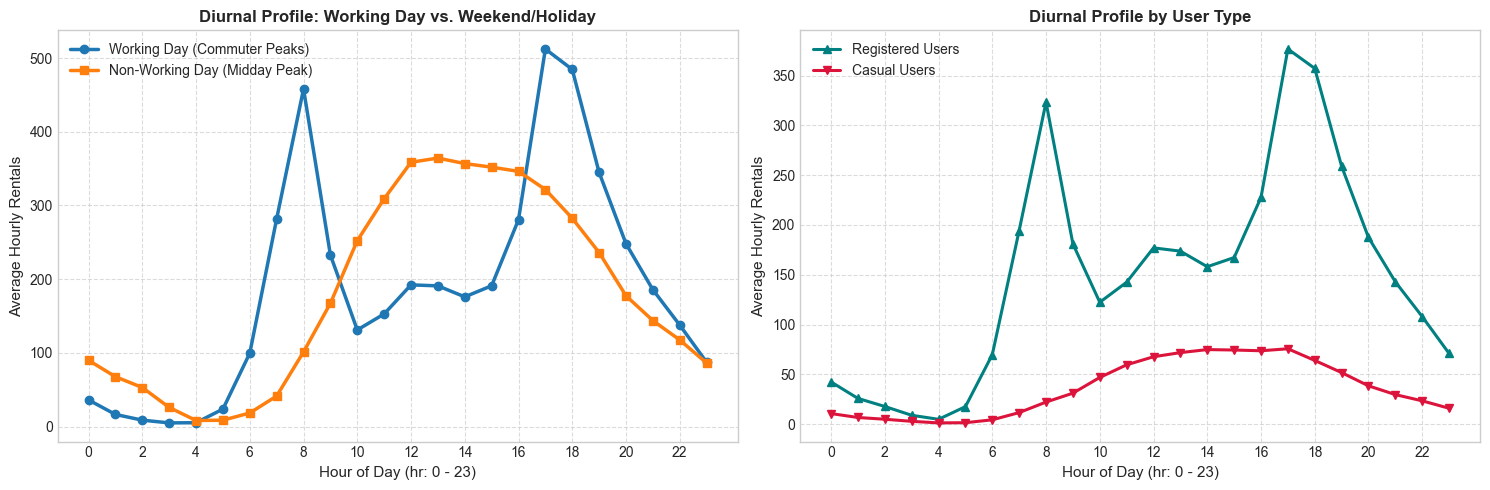

In [33]:
# Hourly diurnal profiles: working day vs weekend/holiday, and user segments
hr_working = train_df.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
hr_reg_cas = train_df.groupby('hr')[['registered', 'casual', 'cnt']].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Working vs non-working day
axes[0].plot(hr_working.index, hr_working[1], marker='o', linewidth=2.5, color='#1f77b4', 
             label='Working Day (Commuter Peaks)')
axes[0].plot(hr_working.index, hr_working[0], marker='s', linewidth=2.5, color='#ff7f0e', 
             label='Non-Working Day (Midday Peak)')
axes[0].set_title('Diurnal Profile: Working Day vs. Weekend/Holiday', fontweight='bold')
axes[0].set_xlabel('Hour of Day (hr: 0 - 23)')
axes[0].set_ylabel('Average Hourly Rentals')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

# User segments across hours
axes[1].plot(hr_reg_cas.index, hr_reg_cas['registered'], marker='^', linewidth=2.2, color='teal', 
             label='Registered Users')
axes[1].plot(hr_reg_cas.index, hr_reg_cas['casual'], marker='v', linewidth=2.2, color='crimson', 
             label='Casual Users')
axes[1].set_title('Diurnal Profile by User Type', fontweight='bold')
axes[1].set_xlabel('Hour of Day (hr: 0 - 23)')
axes[1].set_ylabel('Average Hourly Rentals')
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


Holiday Mean: 156.2 vs Non-Holiday Mean: 186.0 (p = 0.0002)
Workingday Mean: 187.9 vs Non-Workingday Mean: 179.3 (p = 0.0045)


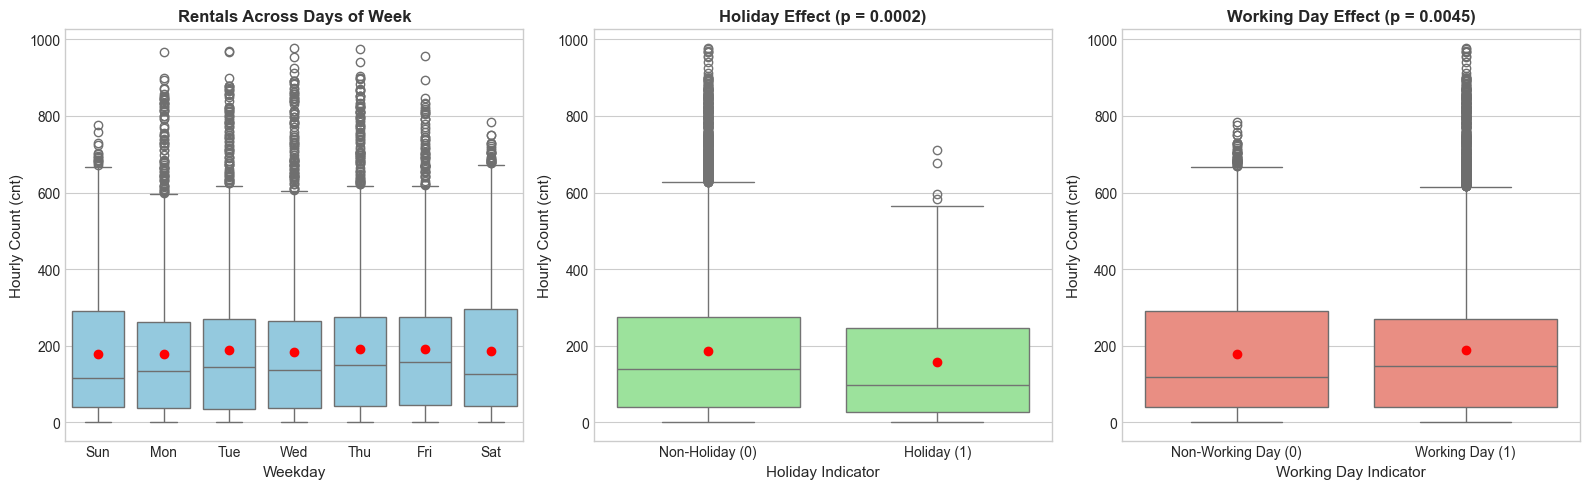

In [34]:
# Weekday, holiday, and working day comparisons
cnt_hol = train_df[train_df['holiday'] == 1]['cnt']
cnt_nonhol = train_df[train_df['holiday'] == 0]['cnt']
ttest_hol = stats.ttest_ind(cnt_hol, cnt_nonhol, equal_var=False)

cnt_work = train_df[train_df['workingday'] == 1]['cnt']
cnt_nonwork = train_df[train_df['workingday'] == 0]['cnt']
ttest_work = stats.ttest_ind(cnt_work, cnt_nonwork, equal_var=False)

print(f"Holiday Mean: {cnt_hol.mean():.1f} vs Non-Holiday Mean: {cnt_nonhol.mean():.1f} (p = {ttest_hol.pvalue:.4f})")
print(f"Workingday Mean: {cnt_work.mean():.1f} vs Non-Workingday Mean: {cnt_nonwork.mean():.1f} (p = {ttest_work.pvalue:.4f})")

weekday_labels = ['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(x='weekday', y='cnt', data=train_df, ax=axes[0], color='skyblue', showmeans=True,
            meanprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red'))
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(weekday_labels)
axes[0].set_title('Rentals Across Days of Week', fontweight='bold')
axes[0].set_xlabel('Weekday')
axes[0].set_ylabel('Hourly Count (cnt)')

sns.boxplot(x='holiday', y='cnt', data=train_df, ax=axes[1], color='lightgreen', showmeans=True,
            meanprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red'))
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Non-Holiday (0)', 'Holiday (1)'])
axes[1].set_title(f'Holiday Effect (p = {ttest_hol.pvalue:.4f})', fontweight='bold')
axes[1].set_xlabel('Holiday Indicator')
axes[1].set_ylabel('Hourly Count (cnt)')

sns.boxplot(x='workingday', y='cnt', data=train_df, ax=axes[2], color='salmon', showmeans=True,
            meanprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red'))
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Non-Working Day (0)', 'Working Day (1)'])
axes[2].set_title(f'Working Day Effect (p = {ttest_work.pvalue:.4f})', fontweight='bold')
axes[2].set_xlabel('Working Day Indicator')
axes[2].set_ylabel('Hourly Count (cnt)')

plt.tight_layout()
plt.show()


In [35]:
# Month vs Season cross-tabulation and Variance Inflation Factor (VIF)
season_month_ct = pd.crosstab(train_df['mnth'], train_df['season'])
print("Cross-Tabulation of Month (mnth) vs Season (season):")
print(season_month_ct)

# VIF diagnostic
vif_features = ['season', 'mnth', 'temp', 'atemp', 'hum', 'windspeed']
X_vif = train_df[vif_features].dropna()
vif_df = pd.DataFrame({
    'Feature': vif_features,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(len(vif_features))]
}).sort_values('VIF', ascending=False)

print("\nVariance Inflation Factors (VIF):")
vif_df


Cross-Tabulation of Month (mnth) vs Season (season):
season     1     2     3    4
mnth                         
1       1429     0     0    0
2       1341     0     0    0
3        949   524     0    0
4          0  1437     0    0
5          0  1488     0    0
6          0   960   480    0
7          0     0  1488    0
8          0     0  1475    0
9          0     0  1053  384
10         0     0     0  743
11         0     0     0  719
12       261     0     0  480

Variance Inflation Factors (VIF):


,Feature,VIF
3,atemp,339.445958
2,temp,315.924470
0,season,25.959027
1,mnth,17.802195
4,hum,6.779558
5,windspeed,2.739683


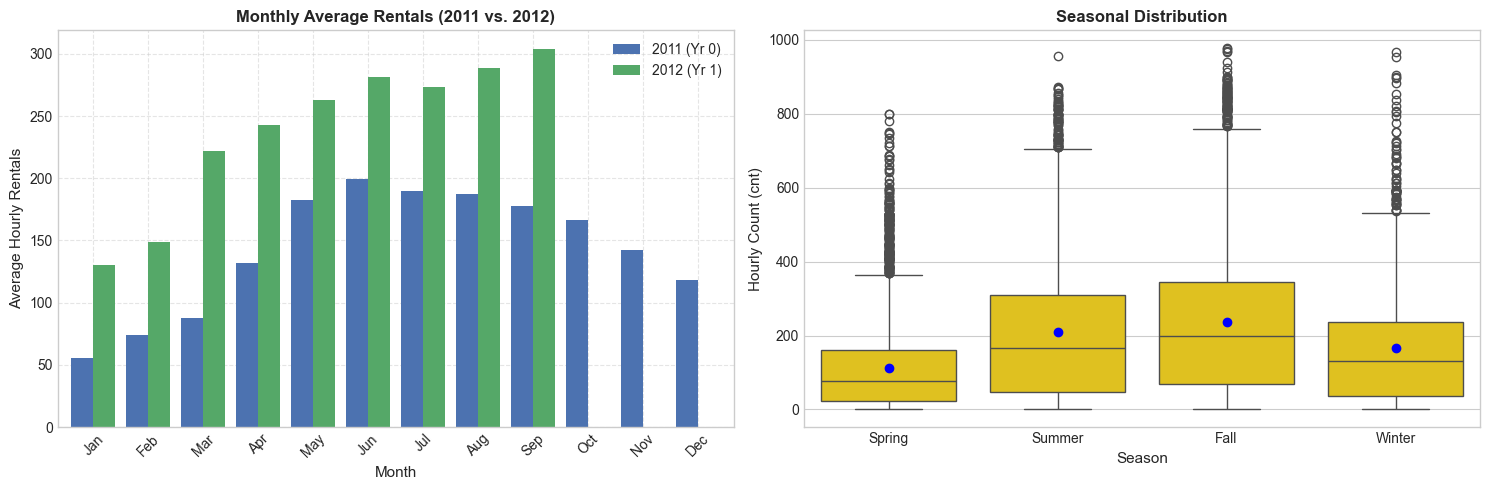

In [36]:
# Monthly and seasonal distribution plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
mnth_yr = train_df.groupby(['mnth', 'yr'])['cnt'].mean().unstack()

mnth_yr.plot(kind='bar', ax=axes[0], color=['#4c72b0', '#55a868'], width=0.8)
axes[0].set_title('Monthly Average Rentals (2011 vs. 2012)', fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Average Hourly Rentals')
axes[0].set_xticks(range(len(mnth_yr)))
axes[0].set_xticklabels([month_names[i-1] for i in mnth_yr.index], rotation=45)
axes[0].legend(['2011 (Yr 0)', '2012 (Yr 1)'])
axes[0].grid(True, linestyle='--', alpha=0.5)

season_names = ['Spring', 'Summer', 'Fall', 'Winter']
sns.boxplot(x='season', y='cnt', data=train_df, ax=axes[1], color='gold', showmeans=True,
            meanprops=dict(marker='o', markerfacecolor='blue', markeredgecolor='blue'))
axes[1].set_xticks(range(4))
axes[1].set_xticklabels(season_names)
axes[1].set_title('Seasonal Distribution', fontweight='bold')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Hourly Count (cnt)')

plt.tight_layout()
plt.show()


### Interpretation & Modeling Decisions: Time Aspects & Multicollinearity
**Author**: [Insert Name]  
<!-- Add your written interpretation of diurnal curves, hour encoding requirements, weekday/holiday dynamics, and season vs month VIF decisions here -->


---
## 6. Question 4: Are There Any Outliers? How Should They Be Adjudicated?
*Code: Generated by AI Assistant*


In [37]:
# Hourly level outlier screening via Tukey's IQR rule
q1 = train_df['cnt'].quantile(0.25)
q3 = train_df['cnt'].quantile(0.75)
iqr = q3 - q1
upper_whisker = q3 + 1.5 * iqr

hourly_outliers = train_df[train_df['cnt'] > upper_whisker]
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Upper Cutoff (Q3 + 1.5*IQR): {upper_whisker:.1f}")
print(f"Flagged hourly observations: {len(hourly_outliers):,} ({len(hourly_outliers)/len(train_df)*100:.2f}% of training set)")
print("\nHours with highest frequency of flagged outliers:")
print(hourly_outliers['hr'].value_counts().head(5))


Q1 = 39.0, Q3 = 275.0, IQR = 236.0
Upper Cutoff (Q3 + 1.5*IQR): 629.0
Flagged hourly observations: 438 (2.88% of training set)

Hours with highest frequency of flagged outliers:
hr
17    132
18    118
8      95
19     20
13     18
Name: count, dtype: int64


In [38]:
# Daily aggregate outlier screening and event cross-referencing
daily_summary = df.groupby(['dteday', 'yr', 'mnth']).agg({
    'cnt': 'sum',
    'weathersit': 'mean',
    'temp_c': 'mean',
    'windspeed_kmh': 'mean',
    'hum_pct': 'mean'
}).reset_index()

# 10 lowest daily totals across entire record
lowest_days = daily_summary.sort_values('cnt').head(10)
print("10 Lowest Demand Days:")
lowest_days[['dteday', 'cnt', 'weathersit', 'temp_c', 'windspeed_kmh']]


10 Lowest Demand Days:


,dteday,cnt,weathersit,temp_c,windspeed_kmh
667,2012-10-29,22,3.000000,18.040000,23.999400
26,2011-01-27,431,1.000000,7.995000,7.627112
725,2012-12-26,441,2.625000,9.976667,21.208571
25,2011-01-26,506,2.937500,8.917500,19.687950
64,2011-03-06,605,2.391304,15.437391,23.000226
68,2011-03-10,623,2.909091,15.952727,17.545777
301,2011-10-29,627,2.583333,10.420833,23.541846
17,2011-01-18,683,2.000000,8.883333,9.833925
340,2011-12-07,705,2.791667,16.810000,17.833725
358,2011-12-25,754,1.000000,11.266087,10.391117


In [39]:
# 10 highest daily totals across entire record
highest_days = daily_summary.sort_values('cnt', ascending=False).head(10)
print("10 Highest Demand Days:")
highest_days[['dteday', 'cnt', 'weathersit', 'temp_c', 'windspeed_kmh']]


10 Highest Demand Days:


,dteday,cnt,weathersit,temp_c,windspeed_kmh
623,2012-09-15,8714,1.208333,24.941667,16.583896
637,2012-09-29,8555,1.083333,22.242500,15.249479
630,2012-09-22,8395,1.000000,26.650000,19.000083
447,2012-03-23,8362,1.583333,24.668333,7.792100
504,2012-05-19,8294,1.000000,24.600000,5.626325
617,2012-09-09,8227,1.041667,25.010000,15.041221
571,2012-07-25,8173,1.000000,29.690833,11.041600
629,2012-09-21,8167,1.000000,24.565833,10.333354
643,2012-10-05,8156,1.000000,25.215000,7.125450
518,2012-06-02,8120,1.166667,23.916667,12.499688


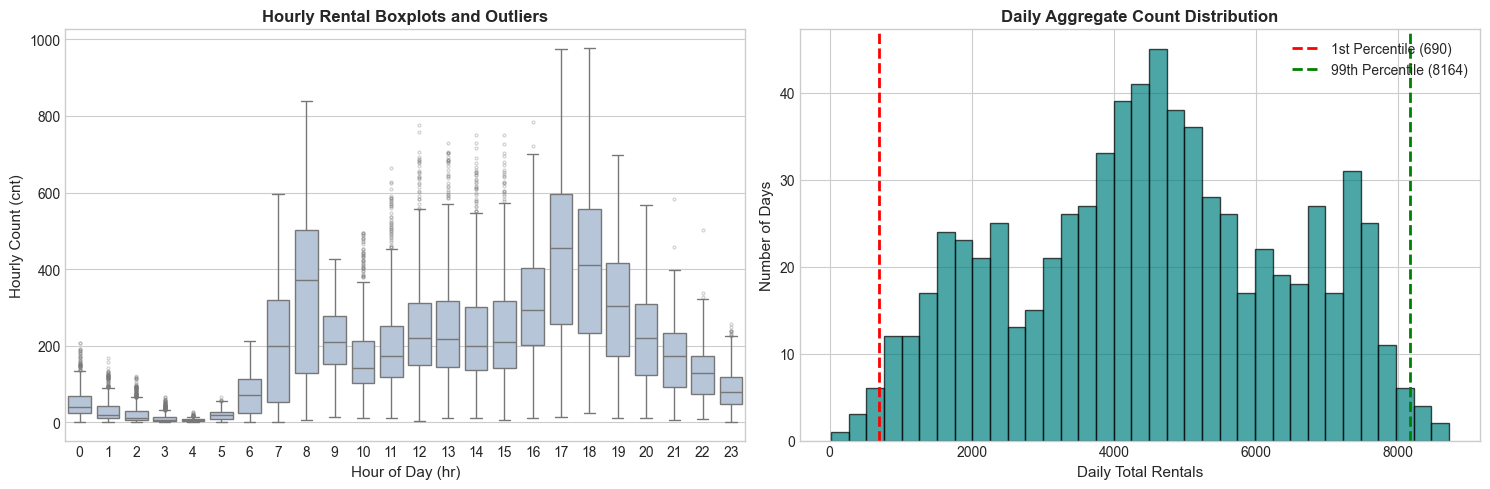

In [40]:
# Distribution plots for hourly and daily scale outliers
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x='hr', y='cnt', data=train_df, ax=axes[0], color='lightsteelblue',
            flierprops=dict(marker='o', markersize=2, alpha=0.3))
axes[0].set_title('Hourly Rental Boxplots and Outliers', fontweight='bold')
axes[0].set_xlabel('Hour of Day (hr)')
axes[0].set_ylabel('Hourly Count (cnt)')

axes[1].hist(daily_summary['cnt'], bins=35, color='teal', edgecolor='black', alpha=0.7)
p1 = daily_summary['cnt'].quantile(0.01)
p99 = daily_summary['cnt'].quantile(0.99)
axes[1].axvline(p1, color='red', linestyle='--', linewidth=2, label=f'1st Percentile ({p1:.0f})')
axes[1].axvline(p99, color='green', linestyle='--', linewidth=2, label=f'99th Percentile ({p99:.0f})')
axes[1].set_title('Daily Aggregate Count Distribution', fontweight='bold')
axes[1].set_xlabel('Daily Total Rentals')
axes[1].set_ylabel('Number of Days')
axes[1].legend()

plt.tight_layout()
plt.show()


### Interpretation & Adjudication Decisions: Outliers & Events
**Author**: [Insert Name]  
<!-- Add your written decisions on whether to retain rush-hour IQR points, and how extreme low-demand weather days (e.g., storms/hurricanes) will be handled in modeling here -->


---
## 7. Question 5: Scatter Plots of How Different Variables Interact with Count
*Code: Generated by AI Assistant*


In [41]:
# Correlation matrix among continuous predictors and targets
cont_vars = ['temp_c', 'atemp_c', 'hum_pct', 'windspeed_kmh']
corr_tbl = train_df[['cnt', 'registered', 'casual'] + cont_vars].corr()
print("Correlation Matrix on Training Set:")
corr_tbl[['cnt', 'registered', 'casual']]


Correlation Matrix on Training Set:


,cnt,registered,casual
cnt,1.000000,0.971641,0.711362
registered,0.971641,1.000000,0.525000
casual,0.711362,0.525000,1.000000
temp_c,0.435885,0.370330,0.468179
atemp_c,0.429326,0.364987,0.460455
hum_pct,-0.329835,-0.283231,-0.345350
windspeed_kmh,0.100032,0.091531,0.087994


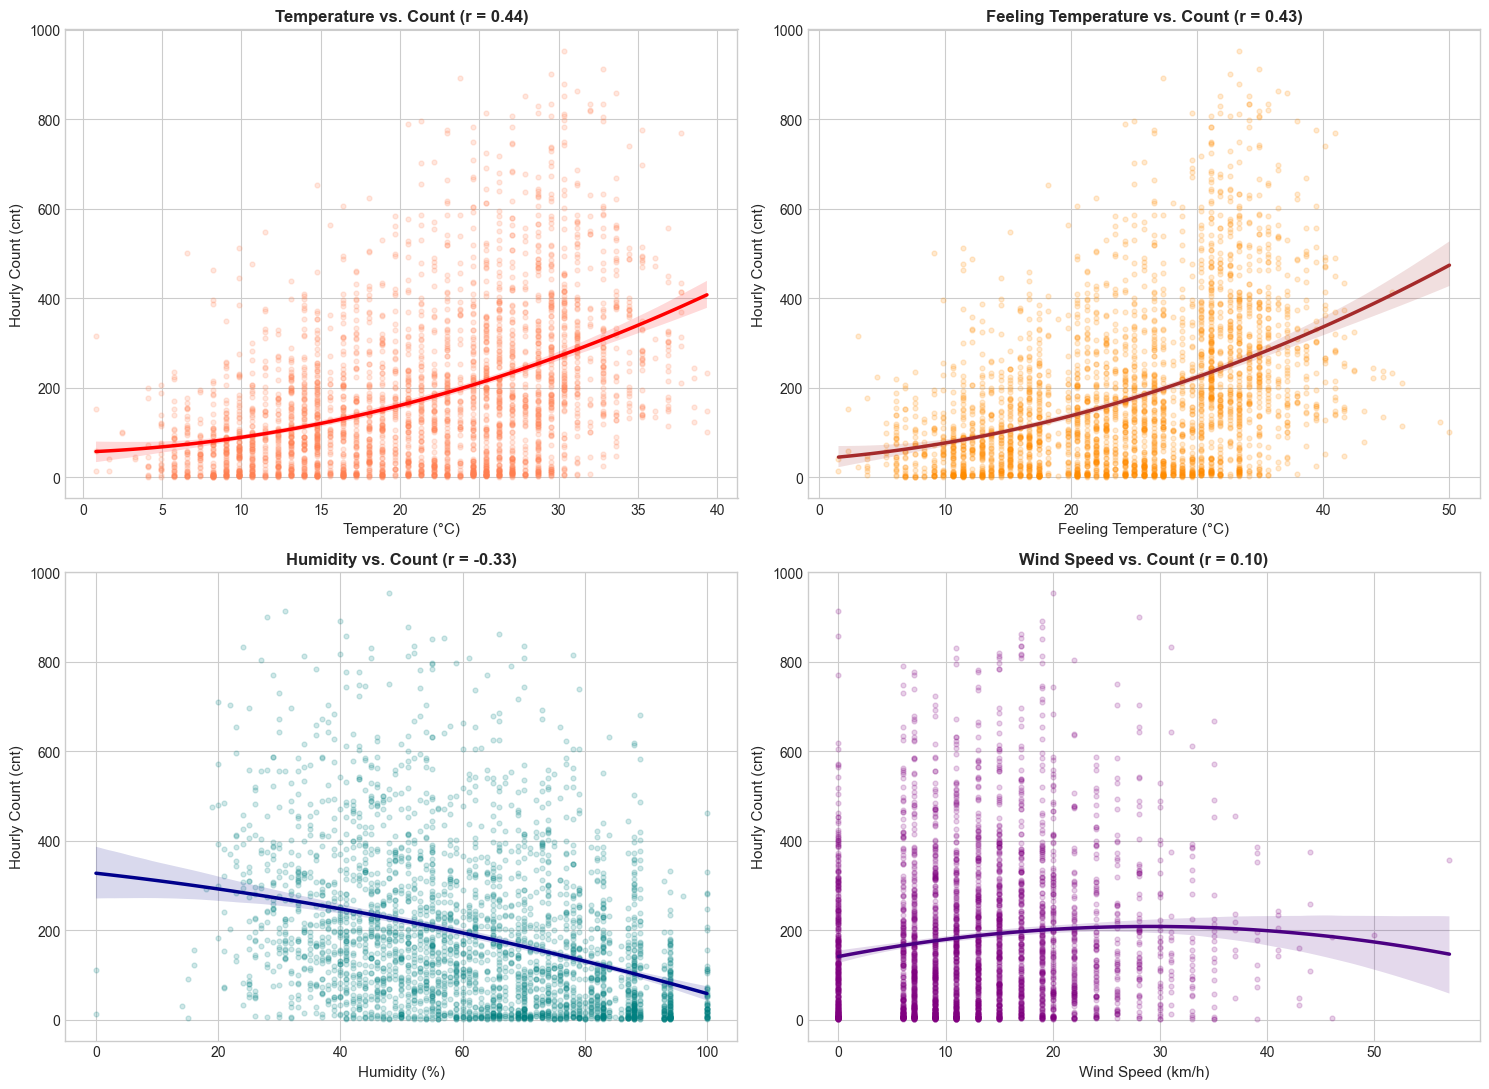

In [42]:
# Scatter plots of continuous predictors against count with order-2 trendlines
sample_train = train_df.sample(3000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

# Temperature
sns.regplot(x='temp_c', y='cnt', data=sample_train, ax=axes[0], order=2,
            scatter_kws={'alpha': 0.18, 'color': 'coral', 's': 12},
            line_kws={'color': 'red', 'linewidth': 2.5})
axes[0].set_title(f"Temperature vs. Count (r = {train_df['temp_c'].corr(train_df['cnt']):.2f})", fontweight='bold')
axes[0].set_xlabel('Temperature (°C)')
axes[0].set_ylabel('Hourly Count (cnt)')

# Feeling Temperature
sns.regplot(x='atemp_c', y='cnt', data=sample_train, ax=axes[1], order=2,
            scatter_kws={'alpha': 0.18, 'color': 'darkorange', 's': 12},
            line_kws={'color': 'brown', 'linewidth': 2.5})
axes[1].set_title(f"Feeling Temperature vs. Count (r = {train_df['atemp_c'].corr(train_df['cnt']):.2f})", fontweight='bold')
axes[1].set_xlabel('Feeling Temperature (°C)')
axes[1].set_ylabel('Hourly Count (cnt)')

# Humidity
sns.regplot(x='hum_pct', y='cnt', data=sample_train, ax=axes[2], order=2,
            scatter_kws={'alpha': 0.18, 'color': 'teal', 's': 12},
            line_kws={'color': 'darkblue', 'linewidth': 2.5})
axes[2].set_title(f"Humidity vs. Count (r = {train_df['hum_pct'].corr(train_df['cnt']):.2f})", fontweight='bold')
axes[2].set_xlabel('Humidity (%)')
axes[2].set_ylabel('Hourly Count (cnt)')

# Windspeed
sns.regplot(x='windspeed_kmh', y='cnt', data=sample_train, ax=axes[3], order=2,
            scatter_kws={'alpha': 0.18, 'color': 'purple', 's': 12},
            line_kws={'color': 'indigo', 'linewidth': 2.5})
axes[3].set_title(f"Wind Speed vs. Count (r = {train_df['windspeed_kmh'].corr(train_df['cnt']):.2f})", fontweight='bold')
axes[3].set_xlabel('Wind Speed (km/h)')
axes[3].set_ylabel('Hourly Count (cnt)')

plt.tight_layout()
plt.show()


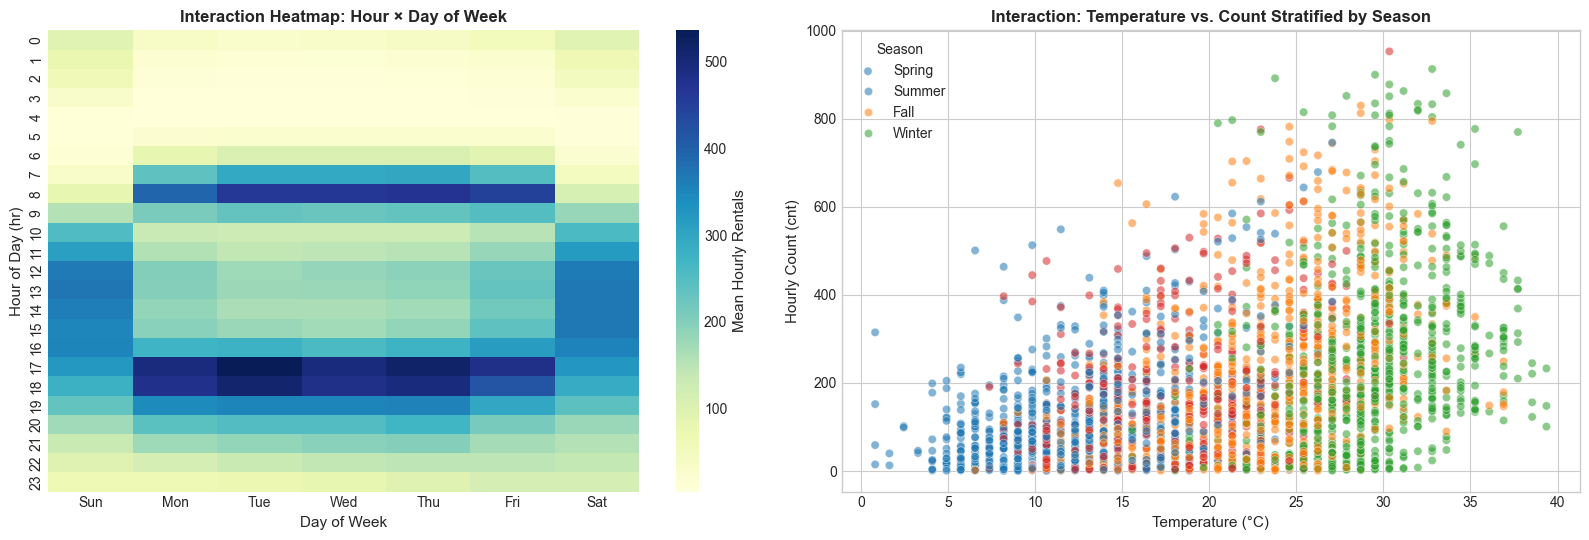

In [43]:
# Interaction plots: Hour x Weekday and Temperature x Season
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Heatmap: Hour x Weekday
hr_wday_pivot = train_df.pivot_table(index='hr', columns='weekday', values='cnt', aggfunc='mean')
hr_wday_pivot.columns = weekday_labels
sns.heatmap(hr_wday_pivot, cmap='YlGnBu', ax=axes[0], cbar_kws={'label': 'Mean Hourly Rentals'})
axes[0].set_title('Interaction Heatmap: Hour × Day of Week', fontweight='bold')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Hour of Day (hr)')

# Scatter: Temperature vs Count by Season
sns.scatterplot(x='temp_c', y='cnt', hue='season', data=sample_train,
                palette='tab10', alpha=0.55, ax=axes[1])
axes[1].set_title('Interaction: Temperature vs. Count Stratified by Season', fontweight='bold')
axes[1].set_xlabel('Temperature (°C)')
axes[1].set_ylabel('Hourly Count (cnt)')
axes[1].legend(title='Season', labels=season_names)

plt.tight_layout()
plt.show()


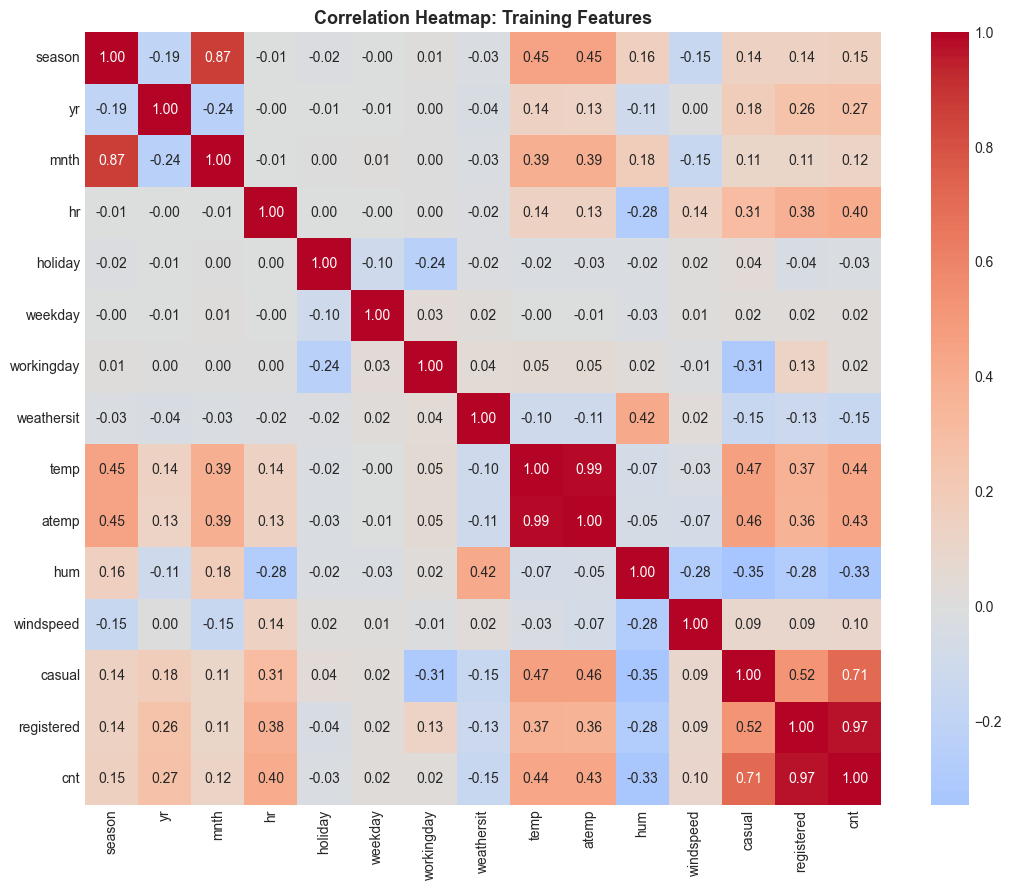

In [44]:
# Correlation heatmap of all numeric variables in training set
plt.figure(figsize=(11, 9))
feature_cols = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit',
                'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
sns.heatmap(train_df[feature_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar=True)
plt.title('Correlation Heatmap: Training Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Interpretation & Modeling Decisions: Nonlinearity & Interactions
**Author**: [Insert Name]  
<!-- Add your written interpretation of continuous predictor relationships, temperature curvature, and key interactions here -->


---
## 8. Intuitive & Behavioral Breakdowns (Simple Descriptive Insights)

Six simple, non-modeling exploratory breakdowns:
1. Weather Severity Breakdown (`weathersit`)
2. Temperature Comfort Zones
3. Humidity & Mugginess Bands
4. Commuters vs. Casual Adverse Weather Reaction
5. Rush Hour Asymmetry (Working Days)
6. The Overnight "Dead Zone" (12:00 AM – 5:00 AM)


### 8.1 Weather Severity Breakdown (`weathersit`)
*Code: Generated by AI Assistant*


Weather Severity Summary Table:
            count  pct_of_days        mean  pct_drop_vs_clear
weathersit                                                   
1           10189    66.984419  200.965257           0.000000
2            3760    24.718953  168.389628          16.209582
3            1259     8.276905  108.386021          46.067284
4               3     0.019723   74.333333          63.011849


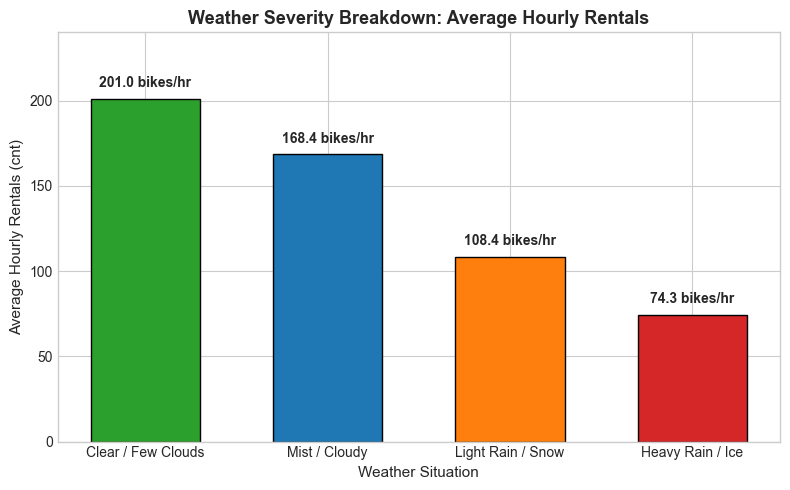

In [45]:
weather_labels = ['Clear / Few Clouds', 'Mist / Cloudy', 'Light Rain / Snow', 'Heavy Rain / Ice']
w_stats = train_df.groupby('weathersit')['cnt'].agg(['count', 'mean', 'median', 'std'])
w_stats['pct_of_days'] = w_stats['count'] / len(train_df) * 100
w_stats['pct_drop_vs_clear'] = (w_stats.loc[1, 'mean'] - w_stats['mean']) / w_stats.loc[1, 'mean'] * 100

print("Weather Severity Summary Table:")
print(w_stats[['count', 'pct_of_days', 'mean', 'pct_drop_vs_clear']])

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar([weather_labels[i-1] for i in w_stats.index], w_stats['mean'], 
              color=['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728'], edgecolor='black', width=0.6)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 5, f"{yval:.1f} bikes/hr", ha='center', va='bottom', fontweight='bold')
ax.set_title('Weather Severity Breakdown: Average Hourly Rentals', fontsize=13, fontweight='bold')
ax.set_xlabel('Weather Situation')
ax.set_ylabel('Average Hourly Rentals (cnt)')
ax.set_ylim(0, 240)
plt.tight_layout()
plt.show()


### Interpretation: Weather Severity Breakdown
**Author**: [Insert Name]  
<!-- Add your written interpretation of weather severity impacts and potential category pooling here -->


### 8.2 Temperature Comfort Zones
*Code: Generated by AI Assistant*


Temperature Comfort Zones Summary:
                count        mean  median
temp_bin                                 
Cold (<10°C)     1768   67.929299    44.0
Cool (10-20°C)   4864  127.498150    93.0
Warm (20-28°C)   5231  201.650162   162.0
Hot (>28°C)      3348  305.370072   276.0


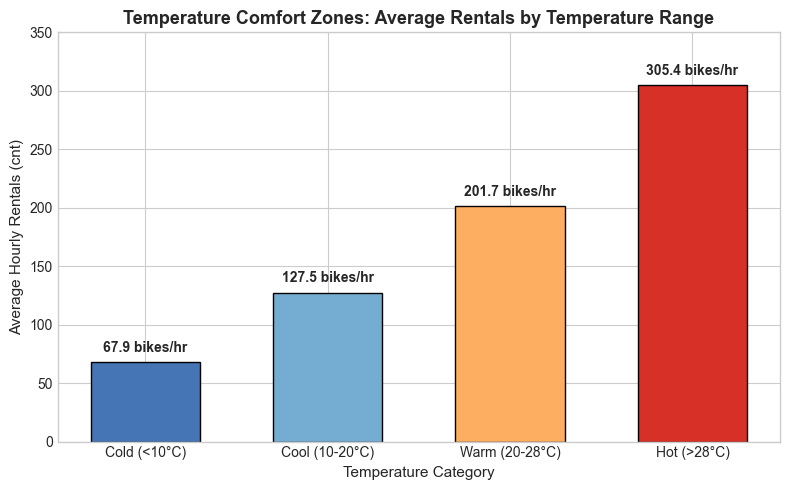

In [46]:
bins_temp = [-10, 10, 20, 28, 50]
labels_temp = ['Cold (<10°C)', 'Cool (10-20°C)', 'Warm (20-28°C)', 'Hot (>28°C)']
train_df['temp_bin'] = pd.cut(train_df['temp_c'], bins=bins_temp, labels=labels_temp)
t_stats = train_df.groupby('temp_bin', observed=False)['cnt'].agg(['count', 'mean', 'median'])

print("Temperature Comfort Zones Summary:")
print(t_stats)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels_temp, t_stats['mean'], color=['#4575b4', '#74add1', '#fdae61', '#d73027'], edgecolor='black', width=0.6)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 6, f"{yval:.1f} bikes/hr", ha='center', va='bottom', fontweight='bold')
ax.set_title('Temperature Comfort Zones: Average Rentals by Temperature Range', fontsize=13, fontweight='bold')
ax.set_xlabel('Temperature Category')
ax.set_ylabel('Average Hourly Rentals (cnt)')
ax.set_ylim(0, 350)
plt.tight_layout()
plt.show()


### Interpretation: Temperature Comfort Zones
**Author**: [Insert Name]  
<!-- Add your written interpretation of ridership changes across temperature ranges here -->


### 8.3 Humidity & Mugginess Bands
*Code: Generated by AI Assistant*


Humidity Bands Summary:
                      count        mean  median
hum_bin                                        
Dry (<40%)             2275  282.188571   239.0
Comfortable (40-65%)   5973  210.271723   174.0
Humid (65-80%)         3490  162.512034   112.0
Muggy (>80%)           3451  101.923790    56.0


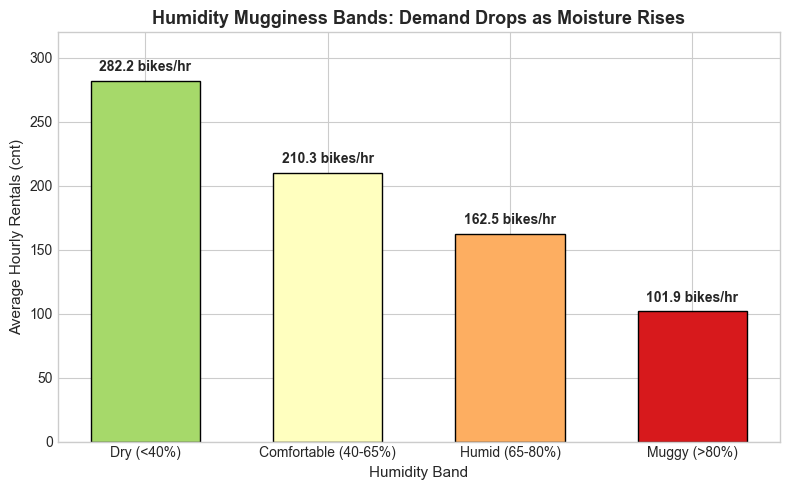

In [47]:
bins_hum = [0, 40, 65, 80, 100]
labels_hum = ['Dry (<40%)', 'Comfortable (40-65%)', 'Humid (65-80%)', 'Muggy (>80%)']
train_df['hum_bin'] = pd.cut(train_df['hum_pct'], bins=bins_hum, labels=labels_hum)
h_stats = train_df.groupby('hum_bin', observed=False)['cnt'].agg(['count', 'mean', 'median'])

print("Humidity Bands Summary:")
print(h_stats)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels_hum, h_stats['mean'], color=['#a6d96a', '#ffffbf', '#fdae61', '#d7191c'], edgecolor='black', width=0.6)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 5, f"{yval:.1f} bikes/hr", ha='center', va='bottom', fontweight='bold')
ax.set_title('Humidity Mugginess Bands: Demand Drops as Moisture Rises', fontsize=13, fontweight='bold')
ax.set_xlabel('Humidity Band')
ax.set_ylabel('Average Hourly Rentals (cnt)')
ax.set_ylim(0, 320)
plt.tight_layout()
plt.show()


### Interpretation: Humidity Bands
**Author**: [Insert Name]  
<!-- Add your written interpretation of humidity thresholds and riding behavior here -->


### 8.4 Commuters vs. Casual Riders in Adverse Weather
*Code: Generated by AI Assistant*


Clear Weather Means  : Registered = 160.1, Casual = 40.9
Rain/Snow Means      : Registered = 92.0, Casual = 16.4
Percentage Drop in Rain: Registered = -42.6%, Casual = -59.8%


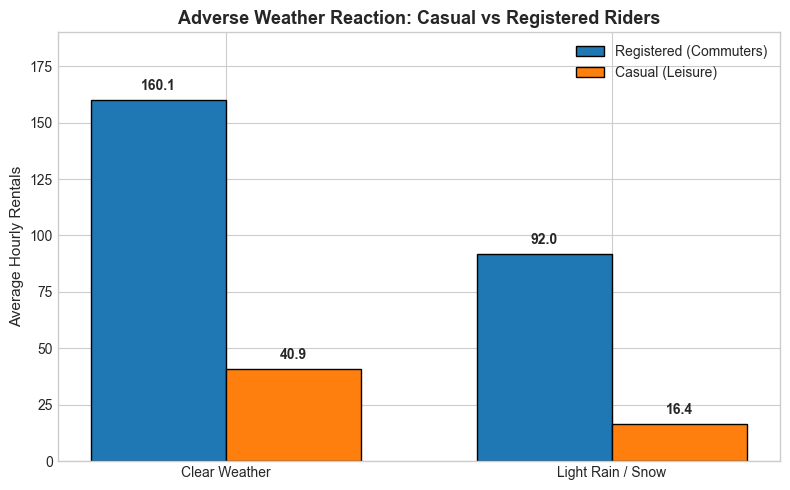

In [48]:
w_user = train_df.groupby('weathersit')[['casual', 'registered', 'cnt']].mean()
w_user_sub = w_user.loc[[1, 3]]  # Clear vs Rain/Snow

reg_drop = (w_user_sub.loc[1, 'registered'] - w_user_sub.loc[3, 'registered']) / w_user_sub.loc[1, 'registered'] * 100
cas_drop = (w_user_sub.loc[1, 'casual'] - w_user_sub.loc[3, 'casual']) / w_user_sub.loc[1, 'casual'] * 100

print(f"Clear Weather Means  : Registered = {w_user_sub.loc[1, 'registered']:.1f}, Casual = {w_user_sub.loc[1, 'casual']:.1f}")
print(f"Rain/Snow Means      : Registered = {w_user_sub.loc[3, 'registered']:.1f}, Casual = {w_user_sub.loc[3, 'casual']:.1f}")
print(f"Percentage Drop in Rain: Registered = -{reg_drop:.1f}%, Casual = -{cas_drop:.1f}%")

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(2)
width = 0.35
b1 = ax.bar(x - width/2, w_user_sub['registered'], width, label='Registered (Commuters)', color='#1f77b4', edgecolor='black')
b2 = ax.bar(x + width/2, w_user_sub['casual'], width, label='Casual (Leisure)', color='#ff7f0e', edgecolor='black')

for b in b1:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 3, f"{b.get_height():.1f}", ha='center', va='bottom', fontweight='bold')
for b in b2:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 3, f"{b.get_height():.1f}", ha='center', va='bottom', fontweight='bold')
    
ax.set_xticks(x)
ax.set_xticklabels(['Clear Weather', 'Light Rain / Snow'])
ax.set_title('Adverse Weather Reaction: Casual vs Registered Riders', fontsize=13, fontweight='bold')
ax.set_ylabel('Average Hourly Rentals')
ax.set_ylim(0, 190)
ax.legend()
plt.tight_layout()
plt.show()


### Interpretation: Commuter vs. Casual Weather Elasticity
**Author**: [Insert Name]  
<!-- Add your written interpretation of user segment elasticity differences during bad weather here -->


### 8.5 Rush Hour Asymmetry on Working Days
*Code: Generated by AI Assistant*


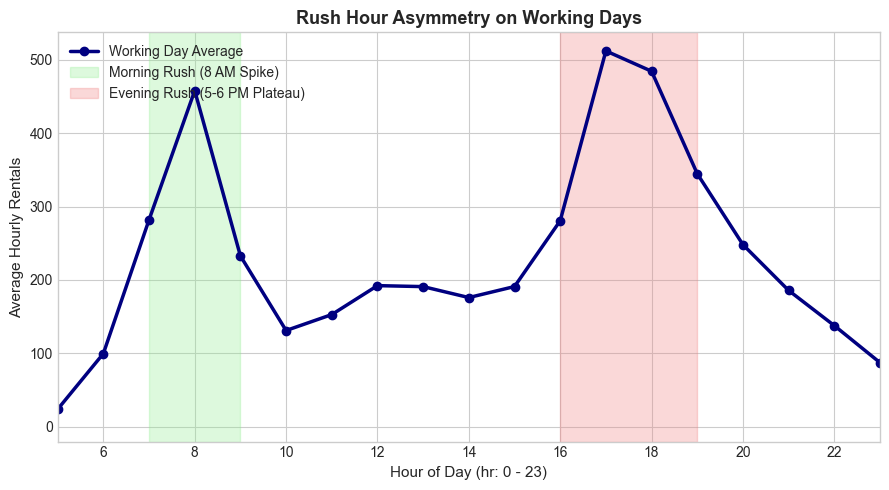

In [49]:
workday_hours = train_df[train_df['workingday'] == 1].groupby('hr')['cnt'].mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(workday_hours.index, workday_hours.values, marker='o', color='navy', linewidth=2.5, label='Working Day Average')
ax.axvspan(7, 9, color='lightgreen', alpha=0.3, label='Morning Rush (8 AM Spike)')
ax.axvspan(16, 19, color='lightcoral', alpha=0.3, label='Evening Rush (5-6 PM Plateau)')
ax.set_title('Rush Hour Asymmetry on Working Days', fontsize=13, fontweight='bold')
ax.set_xlabel('Hour of Day (hr: 0 - 23)')
ax.set_ylabel('Average Hourly Rentals')
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(5, 23)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


### Interpretation: Rush Hour Asymmetry
**Author**: [Insert Name]  
<!-- Add your written interpretation of morning vs evening commute patterns here -->


### 8.6 The Overnight "Dead Zone" (12:00 AM – 5:00 AM)
*Code: Generated by AI Assistant*


Overnight Hours (12 AM - 5 AM) Summary:
         mean  median  min  max
hr                             
0   53.011024    39.0    2  207
1   32.518927    20.0    1  168
2   22.668800    11.0    1  122
3   11.729508     6.0    1   66
4    6.121711     5.0    1   28
5   19.030303    18.0    1   66


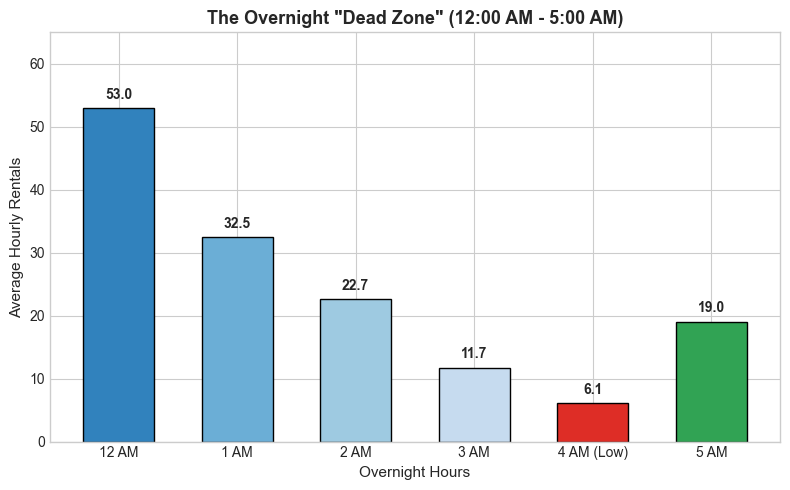

In [50]:
night_stats = train_df[train_df['hr'] <= 5].groupby('hr')['cnt'].agg(['mean', 'median', 'min', 'max'])
night_labels = ['12 AM', '1 AM', '2 AM', '3 AM', '4 AM (Low)', '5 AM']

print("Overnight Hours (12 AM - 5 AM) Summary:")
print(night_stats)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(night_labels, night_stats['mean'], color=['#3182bd', '#6baed6', '#9ecae1', '#c6dbef', '#de2d26', '#31a354'], edgecolor='black', width=0.6)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}", ha='center', va='bottom', fontweight='bold')
ax.set_title('The Overnight "Dead Zone" (12:00 AM - 5:00 AM)', fontsize=13, fontweight='bold')
ax.set_xlabel('Overnight Hours')
ax.set_ylabel('Average Hourly Rentals')
ax.set_ylim(0, 65)
plt.tight_layout()
plt.show()


### Interpretation: Overnight Lows
**Author**: [Insert Name]  
<!-- Add your written interpretation of overnight baseline demand and minimum values here -->


---
## 9. Modeling Synthesis & Decision Blueprint
**Author**: [Insert Name]

<!-- Use this section to record your team's modeling decisions, feature engineering plans, transformation strategies, and regularized regression choices based on the EDA findings above. -->

| Aspect | EDA Observation | Team Modeling Decision | Rationale |
| :--- | :--- | :--- | :--- |
| **Train/Test Split** | | | |
| **Hour (`hr`) Encoding** | | | |
| **Month vs. Season** | | | |
| **Temperature (`temp`, `atemp`)** | | | |
| **Target Transformation ($\log(cnt)$)** | | | |
| **Outlier Handling** | | | |
| **Regularization Strategy** | | | |

---
*End of Notebook 01 EDA.*
